## Исследование данных о российском кинопрокате



**Заказчик этого исследования — Министерство культуры Российской Федерации.
Вам нужно изучить рынок российского кинопроката и выявить текущие тренды. 
Уделите внимание фильмам, которые получили государственную поддержку. 
Попробуйте ответить на вопрос, насколько такие фильмы интересны зрителю.
Вы будете работать с данными, опубликованными на портале открытых данных Министерства культуры. 
Набор данных содержит информацию о прокатных удостоверениях, 
сборах и государственной поддержке фильмов, 
а также информацию с сайта КиноПоиск.**

Исходные данные: две таблицы с данными о:

- прокатных удостоверениях;
- прокате в российских кинотеатрах.


**Стоит две задачи:**
- Определить текущие тренды.
- Определить насколько зрителю интересны фильмы созданные с государственной поддержкой.
   
Выявить тренды помогут данные о кассовых сборах, как впрочем и интерес к фильму (зритель голосует рублём), а так же рейтинги. Хотя все определит анализ данных.
    В любом случае необходимо следовать брифу, так и поступлю. Поехали.

### Шаг 1. Откройте файлы с данными и объедините их в один датафрейм. 

Объедините данные таким образом, чтобы все объекты из датасета `mkrf_movies` обязательно вошли в получившийся датафрейм. 

<div id="accordion">
    <div class="card">
        <div class="card-header" id="headingThree">
            <button class="btn btn-link collapsed" data-toggle="collapse" data-target="#collapseHint_0" aria-expanded="false" aria-controls="collapseHint_0">Подсказка</button>
        </div>
        <div id="collapseHint_0" class="collapse" aria-labelledby="headingThree" data-parent="#accordion">
            <div class="card-body">
Обратите внимание на тип данных столбца, по которому будете соединять датафреймы. Тип данных этих столбцов должен быть одинаковым в обоих датафреймах.
            </div>
        </div>
    </div>
</div>

**Импортируем необходимые для работы библиотеки, посмотрим информацию по таблицам данных и соединим таблицы в один датафрейм для упрощения работы с данными.**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind
import seaborn as sns
pd.options.mode.chained_assignment = None

In [2]:
df1 = pd.read_csv('/datasets/mkrf_movies.csv')
df2 = pd.read_csv('/datasets/mkrf_shows.csv')

In [3]:
df1.head(5)

,title,puNumber,show_start_date,type,film_studio,production_country,director,producer,age_restriction,refundable_support,nonrefundable_support,budget,financing_source,ratings,genres
0,Открытый простор,221048915,2015-11-27T12:00:00.000Z,Художественный,"Тачстоун Пикчерз, Кобальт Пикчерз, Бикон Пикче...",США,Кевин Костнер,"Дэвид Валдес, Кевин Костнер, Джейк Эбертс",«18+» - запрещено для детей,NaN,NaN,NaN,NaN,7.2,"боевик,драма,мелодрама"
1,Особо важное задание,111013716,2016-09-13T12:00:00.000Z,Художественный,"Киностудия ""Мосфильм""",СССР,Е.Матвеев,NaN,«6+» - для детей старше 6 лет,NaN,NaN,NaN,NaN,6.6,"драма,военный"
2,Особо опасен,221038416,2016-10-10T12:00:00.000Z,Художественный,"Юниверсал Пикчерз, Кикстарт Продакшнз, Марк Пл...",США,Тимур Бекмамбетов,"Джим Лемли, Джейсон Нетер, Марк Е.Платт, Яйн Смит",«18+» - запрещено для детей,NaN,NaN,NaN,NaN,6.8,"фантастика,боевик,триллер"
3,Особо опасен,221026916,2016-06-10T12:00:00.000Z,Художественный,"Юниверсал Пикчерз, Кикстарт Продакшнз, Марк Пл...",США,Тимур Бекмамбетов,"Джим Лемли, Джейсон Нетер, Марк Е.Платт, Яйн Смит",«18+» - запрещено для детей,NaN,NaN,NaN,NaN,6.8,"фантастика,боевик,триллер"
4,Особо опасен,221030815,2015-07-29T12:00:00.000Z,Художественный,"Юниверсал Пикчерз, Кикстарт Продакшнз, Марк Пл...",США,Тимур Бекмамбетов,"Джим Лемли, Джейсон Нетер, Марк Е.Платт, Яйн Смит",«18+» - запрещено для детей,NaN,NaN,NaN,NaN,6.8,"фантастика,боевик,триллер"


In [4]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7486 entries, 0 to 7485
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   title                  7486 non-null   object 
 1   puNumber               7486 non-null   object 
 2   show_start_date        7486 non-null   object 
 3   type                   7486 non-null   object 
 4   film_studio            7468 non-null   object 
 5   production_country     7484 non-null   object 
 6   director               7477 non-null   object 
 7   producer               6918 non-null   object 
 8   age_restriction        7486 non-null   object 
 9   refundable_support     332 non-null    float64
 10  nonrefundable_support  332 non-null    float64
 11  budget                 332 non-null    float64
 12  financing_source       332 non-null    object 
 13  ratings                6519 non-null   object 
 14  genres                 6510 non-null   object 
dtypes: f

In [5]:
df2.head(5)

,puNumber,box_office
0,111000113,2.450000e+03
1,111000115,6.104000e+04
2,111000116,1.530300e+08
3,111000117,1.226096e+07
4,111000118,1.636841e+08


In [6]:
df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3158 entries, 0 to 3157
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   puNumber    3158 non-null   int64  
 1   box_office  3158 non-null   float64
dtypes: float64(1), int64(1)
memory usage: 49.5 KB


In [7]:
df1[pd.to_numeric(df1['puNumber'], errors='coerce').isna()]

,title,puNumber,show_start_date,type,film_studio,production_country,director,producer,age_restriction,refundable_support,nonrefundable_support,budget,financing_source,ratings,genres
1797,Курбан-роман. (История с жертвой),нет,2014-05-15T12:00:00.000Z,Художественный,"ФОНД ""ИННОВАЦИЯ""",Россия,С.Юзеев,М.Галицкая,«12+» - для детей старше 12 лет,NaN,NaN,NaN,NaN,NaN,NaN


**У фильма `'Курбан-роман. (История с жертвой)'` вместо номера прокатного удостоверения указано 'нет'. Поищем информацию о нём на сайте [Министерства Культуры РФ](https://culture.gov.ru/). Найдено 2 удостоверения, одно из них с номером `111009614`, другое с 'нет'. Исключим запись о фильме с 'нет', поскольку уже имеется информация об этом фильме с указанным номером удостоверения, нам будет достаточно**

In [8]:
#Исключим запись с 'нет' в столбце 'puNumber' и приведём колонку к целочисленному типу
df1 = df1[df1['puNumber'] != 'нет']
df1['puNumber'] = df1['puNumber'].astype('int64')
df1['puNumber'].dtypes

dtype('int64')

In [9]:
df2['puNumber'] = df2['puNumber'].astype('int64')
df2['puNumber'].dtypes

dtype('int64')

In [10]:
df = df1.merge(df2, how='left', on='puNumber')
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 7485 entries, 0 to 7484
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   title                  7485 non-null   object 
 1   puNumber               7485 non-null   int64  
 2   show_start_date        7485 non-null   object 
 3   type                   7485 non-null   object 
 4   film_studio            7467 non-null   object 
 5   production_country     7483 non-null   object 
 6   director               7476 non-null   object 
 7   producer               6917 non-null   object 
 8   age_restriction        7485 non-null   object 
 9   refundable_support     332 non-null    float64
 10  nonrefundable_support  332 non-null    float64
 11  budget                 332 non-null    float64
 12  financing_source       332 non-null    object 
 13  ratings                6519 non-null   object 
 14  genres                 6510 non-null   object 
 15  box_

In [11]:
df.sample()

,title,puNumber,show_start_date,type,film_studio,production_country,director,producer,age_restriction,refundable_support,nonrefundable_support,budget,financing_source,ratings,genres,box_office
4056,Тюльпан,111007110,2010-07-12T12:00:00.000Z,Художественный,"ООО ""Продюсерская компания ""СЛОВО"", PANDORA FI...",Россия - Германия - Швейцария,С.Дворцевой,"В.Фишер, Г.Сарсенова, Б.Галимгиреев, С.Мелькум...",«16+» - для детей старше 16 лет,NaN,NaN,NaN,NaN,7.0,"мелодрама,комедия",NaN


In [12]:
df.describe()

,puNumber,refundable_support,nonrefundable_support,budget,box_office
count,7.485000e+03,3.320000e+02,3.320000e+02,3.320000e+02,3.158000e+03
mean,1.351966e+08,1.186446e+07,4.898099e+07,1.272297e+08,7.647870e+07
std,3.835292e+07,2.491656e+07,5.998012e+07,1.885883e+08,2.403531e+08
min,1.811096e+06,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,1.120251e+08,0.000000e+00,2.500000e+07,4.200000e+07,8.623900e+04
50%,1.210155e+08,0.000000e+00,3.000000e+07,6.864992e+07,2.327988e+06
75%,1.240033e+08,1.500000e+07,4.037500e+07,1.419853e+08,2.397967e+07
max,2.310011e+08,1.800000e+08,4.000000e+08,2.305074e+09,3.073569e+09


**Данные сшили в один датафрейм, можно приступить к изучению и предобработке данных**

### Шаг 2. Предобработка данных

#### Шаг 2.1. Проверьте типы данных

- Проверьте типы данных в датафрейме и преобразуйте их там, где это необходимо.

In [13]:
#Посмотрим на типы данных
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 7485 entries, 0 to 7484
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   title                  7485 non-null   object 
 1   puNumber               7485 non-null   int64  
 2   show_start_date        7485 non-null   object 
 3   type                   7485 non-null   object 
 4   film_studio            7467 non-null   object 
 5   production_country     7483 non-null   object 
 6   director               7476 non-null   object 
 7   producer               6917 non-null   object 
 8   age_restriction        7485 non-null   object 
 9   refundable_support     332 non-null    float64
 10  nonrefundable_support  332 non-null    float64
 11  budget                 332 non-null    float64
 12  financing_source       332 non-null    object 
 13  ratings                6519 non-null   object 
 14  genres                 6510 non-null   object 
 15  box_

**Наименование столбцов аккуратные, кроме puNumber, переименуем его. 
Приведем типы данных к необходимым: 
1.show_start_date к дате.
2. ratings к числам с плавающей точкой.**

In [14]:
df.rename(columns = {'puNumber': 'pu_number'}, inplace=True)

In [15]:
#Приведем дату выхода фильма к нормальной датировке
df['show_start_date'] = pd.to_datetime(df['show_start_date'], format = '%Y-%m-%d')

In [16]:
#Посмотрим столбец ratings.
df['ratings'].unique()

array(['7.2', '6.6', '6.8', '7.7', '8.3', '8.0', '7.8', '8.1', '7.1',
       '6.0', '7.4', '5.8', '8.7', '6.3', '6.9', '5.0', '4.3', '7.3',
       '7.0', '6.4', nan, '8.2', '7.5', '6.7', '7.9', '5.9', '6.2', '5.6',
       '6.5', '2.4', '7.6', '6.1', '8.6', '8.5', '8.8', '5.5', '5.1',
       '5.7', '5.4', '99%', '4.4', '4.5', '5.3', '4.1', '8.4', '2.6',
       '3.8', '4.6', '4.8', '4.0', '3.0', '1.6', '4.2', '5.2', '4.7',
       '4.9', '3.9', '2.7', '3.3', '2.9', '28%', '3.7', '1.4', '3.1',
       '97%', '3.5', '3.2', '2.8', '1.5', '2.1', '2.5', '9.2', '3.4',
       '1.1', '3.6', '83%', '64%', '91%', '94%', '62%', '79%', '90%',
       '19%', '88%', '1.0', '89%', '1.3', '1.9', '1.8', '1.2', '1.7',
       '9.0', '98%', '8.9', '9.1'], dtype=object)

In [17]:
df['ratings'].apply(type).value_counts()

<class 'str'>      6519
<class 'float'>     966
Name: ratings, dtype: int64

**Странная оценка КиноПоиска в 99%, видимо это процент ожидаемости выхода фильма, так же имеются пропуски, и разный тип данных, приведём всё к 'float', но прежде посмотрим фильмы с оценками в процентах**

In [18]:
df.loc[(df['ratings'].isna() == False) & 
       (df['ratings'].str.contains('%')), ['title', 'pu_number', 'genres', 'ratings']].sample(20)

,title,pu_number,genres,ratings
3584,"Машины Страшилки. Серия ""Жутчайшая повесть о п...",114003916,"мультфильм,ужасы,фэнтези",97%
2437,Самый рыжий Лис,111012715,"фэнтези,семейный",62%
6881,Животные рядом со Святыми,112003719,"криминал,драма",99%
3785,Охотники,111017816,"фантастика,комедия,боевик",89%
6615,ОТ ВОЙНЫ ДО НАШИХ ДНЕЙ,111026518,"фантастика,боевик",98%
259,Прошлое,221030715,"ужасы,триллер,драма",99%
5331,Добыча.,121009411,"фантастика,боевик,триллер",88%
2679,Год Белого Слона,111003915,семейный,79%
5820,Свинья,121007018,"триллер,драма",94%
6736,Колесо времени,111003219,"фэнтези,приключения",98%


**Больше похоже на баг в формировании оценок, 99% ожидаемость фильма 'Сказка о добре и Вре', слабо верится. Заменим оценки в процентах на пропуски, изменим тип данных столбца на float**

In [19]:
df.loc[(df['ratings'].isna() == False) & 
       (df['ratings'].str.contains('%')), 'ratings'] = np.nan

df['ratings'] = df['ratings'].astype('float64')
df.dtypes

title                                 object
pu_number                              int64
show_start_date          datetime64[ns, UTC]
type                                  object
film_studio                           object
production_country                    object
director                              object
producer                              object
age_restriction                       object
refundable_support                   float64
nonrefundable_support                float64
budget                               float64
financing_source                      object
ratings                              float64
genres                                object
box_office                           float64
dtype: object

In [20]:
display(df['ratings'])
df['ratings'].unique()

0       7.2
1       6.6
2       6.8
3       6.8
4       6.8
       ... 
7480    NaN
7481    5.4
7482    NaN
7483    NaN
7484    6.3
Name: ratings, Length: 7485, dtype: float64

array([7.2, 6.6, 6.8, 7.7, 8.3, 8. , 7.8, 8.1, 7.1, 6. , 7.4, 5.8, 8.7,
       6.3, 6.9, 5. , 4.3, 7.3, 7. , 6.4, nan, 8.2, 7.5, 6.7, 7.9, 5.9,
       6.2, 5.6, 6.5, 2.4, 7.6, 6.1, 8.6, 8.5, 8.8, 5.5, 5.1, 5.7, 5.4,
       4.4, 4.5, 5.3, 4.1, 8.4, 2.6, 3.8, 4.6, 4.8, 4. , 3. , 1.6, 4.2,
       5.2, 4.7, 4.9, 3.9, 2.7, 3.3, 2.9, 3.7, 1.4, 3.1, 3.5, 3.2, 2.8,
       1.5, 2.1, 2.5, 9.2, 3.4, 1.1, 3.6, 1. , 1.3, 1.9, 1.8, 1.2, 1.7,
       9. , 8.9, 9.1])

**Остальные типы данных вроде в порядке, не помешают обработке и анализу.**

#### Шаг 2.2. Изучите пропуски в датафрейме

- Объясните, почему заполнили пропуски определённым образом или почему не стали этого делать.

**Посмотрим визуально что происходит с пропусками и какой процент пропусков данных**

In [21]:
pd.DataFrame(round(df.isna().mean()*100,)).style.background_gradient('coolwarm')

,0
title,0.000000
pu_number,0.000000
show_start_date,0.000000
type,0.000000
film_studio,0.000000
production_country,0.000000
director,0.000000
producer,8.000000
age_restriction,0.000000
refundable_support,96.000000


**Значительная часть пропусков в финансовых данных о госсподдержке, финансировании, бюджете и  кассовых сборах.
Финансовые данные не заполнить ни средним, ни медианным значением. Тут скорее подойдет анализ срезов данных по стране производителю, поскольку господдержка распространялась не на все прокатные фильмы. Потому и процент пропусков большой, что среди общего количества прокатных фильмов малый процент Российского производства.
Отсутствующие данные в столбцах с типом данных float64 нельзя заполнять никакими значениями, повлияет на статистику, а пропущенные значения не учитываются. По той же причине оставим пропуски в столбцах 'box_office' и 'ratings'.**

In [22]:
#Посмотрим что с пропусками по кассовым сборам
mask = (pd.to_numeric(df['box_office'], errors='ignore').isna())
df.loc[mask][['title', 'box_office']]

,title,box_office
0,Открытый простор,NaN
1,Особо важное задание,NaN
2,Особо опасен,NaN
3,Особо опасен,NaN
4,Особо опасен,NaN
...,...,...
7480,Сад художника: Американский импрессионизм,NaN
7481,Звериная ярость,NaN
7482,Щенячий патруль: Скорей спешим на помощь!,NaN
7483,"Машины песенки. Серия ""Испанские мотивы""",NaN


**Видны дубликаты, поработаем с ними в будущем, сейчас этот столбец оставим без изменений**

**Заполним пропуски в столбце 'genres' в соответствии с типом фильма**

In [23]:
display(df.groupby('type')['genres'].unique())
print('\n'.join(df.loc[df['genres'].isna(), 'type'].unique()))

type
 Анимационный                                  [мультфильм,комедия,приключения]
 Художественный               [триллер,комедия, военный,драма,история, комед...
Анимационный                  [мультфильм,фантастика,фэнтези, мультфильм,фэн...
Документальный                [документальный,короткометражка, документальны...
Музыкально-развлекательный                                     [документальный]
Научно-популярный             [аниме,мультфильм,мелодрама, триллер,драма, фа...
Прочие                        [мультфильм,приключения,семейный, документальн...
Художественный                [боевик,драма,мелодрама, драма,военный, фантас...
Name: genres, dtype: object

Художественный
Прочие
Документальный
Анимационный
Научно-популярный
 Художественный


In [24]:
df.loc[(df['type'] == 'Анимационный') & (df['genres'].isna()), 'genres'] = 'мультфильм'
df.loc[((df['type'] == 'Документальный') | (df['type'] == 'Научно-популярный')) & 
       (df['genres'].isna()), 'genres'] = 'документальный'
df['genres'] = df['genres'].fillna('не указан')

**Посмотрим пропуски в столбце 'producer'**

In [25]:
df.loc[df['producer'].isna(), ['title', 'film_studio', 'production_country', 'director', 'producer']].sample(10)

,title,film_studio,production_country,director,producer
5583,Путешествие (киноальманах),"Киностудия ""Мосфильм""",СССР,"Д.Фирсова, И.Туманян, И.Селезнева",NaN
5430,Тоска по дикой природе,"Киноакадемия Баден-Вюртемберг, ЭпикСкейпс",Германия,Марк Циммерманн,NaN
3269,Сафари (2016),Ульрих Зайдль Фильм Продукцион ГмбХ,Австрия,Ульрих Зайдль,NaN
6353,Проза бродячих псов. Фильм,Кадокава,Япония,Такуя Игараси,NaN
1972,"Частный детектив, или операция ""Кооперация""","ГТПО ""Мосфильм""",СССР,Л.Гайдай,NaN
3095,Ленин в 1918 году.,"Киностудия ""Мосфильм""",СССР,М.Ромм,NaN
2557,Город принял,"Киностудия ""Мосфильм""",СССР,В.Максаков,NaN
1655,ВИЙ 3D,"ООО ""Русская Фильм Группа""",Россия,О.Степченко,NaN
5580,Трактир на Пятницкой,"Киностудия ""Мосфильм""",СССР,А.Файнциммер,NaN
2113,Мертвые души,"Киностудия ""Мосфильм""",СССР,Л.Трауберг,NaN


**В столбце 'producer' для страны-производителя 'СССР' заменим пропуски значением 'Госкино СССР'. 
Для других стран пропуски заменим на 'unknown'.**

In [26]:
df.loc[(df['producer'].isna()) & 
        (df['production_country'].str.contains('СССР')), 'producer'] = 'Госкино СССР'

df['producer'] = df['producer'].fillna('unknown')

**Заполним пропуски по столбцам film_studio, director, financing_source на 'unknown' на текущие задачи эти данные сущесственного влияния не имеют.**

In [27]:
df['film_studio'] = df['film_studio'].fillna('unknown')
df['director'] = df['director'].fillna('unknown')
df['financing_source'] = df['financing_source'].fillna('unknown')

**Посмотрим на записи с пропусками страны-производителя, эти данные могут повлиять на анализ.**

In [28]:
df.loc[df['production_country'].isna(), 
       ['title', 'pu_number', 'film_studio', 'production_country', 'director', 'producer']]

,title,pu_number,film_studio,production_country,director,producer
3185,"Детский юмористический киножурнал ""Ералаш. Ну ...",111001216,"ООО ""Продюсерский центр ЕРАЛАШ""",NaN,"Р.Светлов, И.Магитон, А.Арутюнян, Л.Мирский, А...","ООО ""Продюсерский центр ЕРАЛАШ"""
4440,Мульт личности. Выпуск 5,214000410,unknown,NaN,unknown,unknown


**Два пропуска с явной страной производителем Россия, заполним пропуски**

In [29]:
df['production_country'] = df['production_country'].fillna('Россия')

In [30]:
#Обновим данные
pd.DataFrame(round(df.isna().mean()*100,)).style.background_gradient('coolwarm')

,0
title,0.000000
pu_number,0.000000
show_start_date,0.000000
type,0.000000
film_studio,0.000000
production_country,0.000000
director,0.000000
producer,0.000000
age_restriction,0.000000
refundable_support,96.000000


**Изучили данные на предмет пропусков, заполнили достоверными значениями. В столбцах с количественным типом данных пропуски оставили, чтобы не вносить искажения статистики. В столбцах с категорийными данными, пропущенные значения заменили на значения 'unknown'.**

#### Шаг 2.3. Изучите дубликаты в датафрейме
- Проверьте, есть ли в данных дубликаты. Опишите причины, которые могли повлиять на появление дублей.

In [31]:
df.duplicated().sum()

0

**Явных дубликатов не обнаружено, посмотрим внутри данных**

In [32]:
#Приведем все названия к нижнему регистру
df['title'] = df['title'].str.lower()

In [33]:
df['title'].sort_values().unique()
df['title']

0                                   открытый простор
1                               особо важное задание
2                                       особо опасен
3                                       особо опасен
4                                       особо опасен
                            ...                     
7480       сад художника: американский импрессионизм
7481                                 звериная ярость
7482       щенячий патруль: скорей спешим на помощь!
7483        машины песенки. серия "испанские мотивы"
7484    машины песенки. серия "когда цветут кактусы"
Name: title, Length: 7485, dtype: object

In [34]:
df.head(10)

,title,pu_number,show_start_date,type,film_studio,production_country,director,producer,age_restriction,refundable_support,nonrefundable_support,budget,financing_source,ratings,genres,box_office
0,открытый простор,221048915,2015-11-27 12:00:00+00:00,Художественный,"Тачстоун Пикчерз, Кобальт Пикчерз, Бикон Пикче...",США,Кевин Костнер,"Дэвид Валдес, Кевин Костнер, Джейк Эбертс",«18+» - запрещено для детей,NaN,NaN,NaN,unknown,7.2,"боевик,драма,мелодрама",NaN
1,особо важное задание,111013716,2016-09-13 12:00:00+00:00,Художественный,"Киностудия ""Мосфильм""",СССР,Е.Матвеев,Госкино СССР,«6+» - для детей старше 6 лет,NaN,NaN,NaN,unknown,6.6,"драма,военный",NaN
2,особо опасен,221038416,2016-10-10 12:00:00+00:00,Художественный,"Юниверсал Пикчерз, Кикстарт Продакшнз, Марк Пл...",США,Тимур Бекмамбетов,"Джим Лемли, Джейсон Нетер, Марк Е.Платт, Яйн Смит",«18+» - запрещено для детей,NaN,NaN,NaN,unknown,6.8,"фантастика,боевик,триллер",NaN
3,особо опасен,221026916,2016-06-10 12:00:00+00:00,Художественный,"Юниверсал Пикчерз, Кикстарт Продакшнз, Марк Пл...",США,Тимур Бекмамбетов,"Джим Лемли, Джейсон Нетер, Марк Е.Платт, Яйн Смит",«18+» - запрещено для детей,NaN,NaN,NaN,unknown,6.8,"фантастика,боевик,триллер",NaN
4,особо опасен,221030815,2015-07-29 12:00:00+00:00,Художественный,"Юниверсал Пикчерз, Кикстарт Продакшнз, Марк Пл...",США,Тимур Бекмамбетов,"Джим Лемли, Джейсон Нетер, Марк Е.Платт, Яйн Смит",«18+» - запрещено для детей,NaN,NaN,NaN,unknown,6.8,"фантастика,боевик,триллер",NaN
5,остановился поезд,111013816,2016-09-13 12:00:00+00:00,Художественный,"Киностудия ""Мосфильм""",СССР,В.Абдрашитов,Госкино СССР,«6+» - для детей старше 6 лет,NaN,NaN,NaN,unknown,7.7,драма,NaN
6,любовь и голуби,111007013,2013-10-18 12:00:00+00:00,Художественный,"Киностудия ""Мосфильм""",СССР,В.Меньшов,Госкино СССР,«12+» - для детей старше 12 лет,NaN,NaN,NaN,unknown,8.3,"мелодрама,комедия",2700.0
7,любовь и сигареты,221074614,2014-12-29 12:00:00+00:00,Художественный,"Юнайтед Артистс, Грин Стрит Филмз, Айкон Интер...",США,Джон Туртурро,"Джон Пенотти, Джон Туртурро",«18+» - запрещено для детей,NaN,NaN,NaN,unknown,6.6,"мюзикл,мелодрама,комедия",NaN
8,отпетые мошенники.,121011416,2016-05-05 12:00:00+00:00,Художественный,"Пульсар Продюксьон, ТФ1 Фильм",Франция,Эрик Беснард,Патрис Леду,«18+» - запрещено для детей,NaN,NaN,NaN,unknown,8.0,"комедия,криминал",NaN
9,отпуск за свой счет,111019114,2014-12-01 12:00:00+00:00,Художественный,"Киностудия ""Мосфильм"", Телевидение ВНР","СССР, Венгрия",В.Титов,Госкино СССР,«12+» - для детей старше 12 лет,NaN,NaN,NaN,unknown,7.8,"мелодрама,комедия",NaN


**Видно, что это не дубликаты, один и тот же фильм с разными прокатными удостоверениями, всё в порядке. Прокатные удостоверения на фильм выдаются для разных носителей информации (ТВ, DVD и т.д.) отдельно. Посмотрим дубликаты в прокатных удостоверениях.**

In [35]:
df.loc[df['pu_number'].duplicated(keep=False), ['title', 'pu_number', 'director']]

,title,pu_number,director
4637,как жениться и остаться холостым,221154310,Эрик Лартиго
4638,иоанна - женщина на папском престоле /по роман...,221154310,Зенке Вортманн
5066,анализируй это!,221054410,ХЭрольд Рэмис
5067,анализируй то!,221054410,Гарольд Реймис


**У фильмов 'Как жениться и остаться холостым' и 'Иоанна - женщина на папском престоле' согласно сайту Министерства Культуры РФ несколько прокатных удостоверений и номер '221154310' так же дублируется, заменим номер для фильма 'Как жениться и остаться холостым' на первое из списка '221333607'. Фильмы 'Анализируй это!' и 'Анализируй то!' разные фильмы и та же ситуация. Заменим номер фильма 'Анализируй то!' - '121004303'. Ошибки видимо появились в результате человеческого фактора при заполнении номеров.**

In [36]:
df.loc[4637, 'pu_number'] = 221333607
df.loc[5067, 'pu_number'] = 121004303

In [37]:
df.loc[df['pu_number'].duplicated(keep=False), ['title', 'pu_number', 'director']]

,title,pu_number,director


#### Шаг 2.4. Изучите категориальные значения

- Посмотрите, какая общая проблема встречается почти во всех категориальных столбцах;
- Исправьте проблемные значения в поле `type`.

<div id="accordion">
    <div class="card">
        <div class="card-header" id="headingThree">
            <button class="btn btn-link collapsed" data-toggle="collapse" data-target="#collapseHint_1" aria-expanded="false" aria-controls="collapseHint_1">Подсказка</button>
        </div>
        <div id="collapseHint_1" class="collapse" aria-labelledby="headingThree" data-parent="#accordion">
            <div class="card-body">
В поле <code>type</code> есть несколько значений, у которых появился пробел в начале строки. Самый простой способ их «починить» -- использовать метод <a href="https://pandas.pydata.org/docs/reference/api/pandas.Series.str.strip.html#pandas.Series.str.strip">.str.strip</a>. Этот метод удаляет все пробелы, которые встречаются в начале и в конце строки. Применяют его таким образом:<br>
<code>df['type'].str.strip()</code>
            </div>
        </div>
    </div>
</div>

**Категории в виде названий и имен, сложны для обработки, сложны для визуальной работы, данные сложны для фильтрования по типу обращения, возможны ошибки в категориях допущенные при заполнении. Посмотрим внутри данных.**

In [38]:
df['type'].value_counts()

Художественный                4519
 Художественный               1389
Анимационный                   828
Прочие                         406
Документальный                 288
Научно-популярный               53
Музыкально-развлекательный       1
 Анимационный                    1
Name: type, dtype: int64

In [39]:
#Удалим лишний пробел в 'type'
df['type'].str.strip()

0       Художественный
1       Художественный
2       Художественный
3       Художественный
4       Художественный
             ...      
7480            Прочие
7481    Художественный
7482    Художественный
7483      Анимационный
7484      Анимационный
Name: type, Length: 7485, dtype: object

In [40]:
df['type'].unique()

array(['Художественный', 'Анимационный', 'Прочие', 'Документальный',
       'Научно-популярный', ' Художественный', ' Анимационный',
       'Музыкально-развлекательный'], dtype=object)

**Пробел остался, попробуем убрать по другому**

In [41]:
df['type'].replace(
    {' Художественный': 'Художественный', ' Анимационный': 'Анимационный'}, inplace=True
)
df['type'].value_counts()

Художественный                5908
Анимационный                   829
Прочие                         406
Документальный                 288
Научно-популярный               53
Музыкально-развлекательный       1
Name: type, dtype: int64

In [42]:
df['film_studio'].value_counts().head()

Киностудия "Мосфильм"    341
ООО "Мульт в кино"        57
Анимаккорд Лтд            23
unknown                   18
ООО "Мульт в кино"        18
Name: film_studio, dtype: int64

In [43]:
df['age_restriction'].value_counts()

«16+» - для детей старше 16 лет           2851
«18+» - запрещено для детей               1605
«12+» - для детей старше 12 лет           1592
«0+» - для любой зрительской аудитории     811
«6+» - для детей старше 6 лет              626
Name: age_restriction, dtype: int64

In [44]:
df['genres'].value_counts()

не указан                     573
драма                         476
комедия                       352
мультфильм                    280
документальный                228
                             ... 
мюзикл                          1
триллер,мелодрама,детектив      1
драма,фантастика,ужасы          1
боевик,криминал,драма           1
детектив,боевик,история         1
Name: genres, Length: 743, dtype: int64

**'Нe указан' менять не будем, то же что 'unknow'. В остальном всё в порядке**

In [45]:
df['production_country'].unique()

array(['США', 'СССР', 'Франция', 'СССР, Венгрия',
       'Германия-Великобритания', 'Великобритания - Италия',
       'Чехословакия', 'США - Франция - Турция', 'Новая Зеландия',
       'Канада - Франция - Испания', 'США-Германия',
       'США - Великобритания', 'Великобритания', 'США - Германия',
       'Франция - Мексика - США', 'Россия, Казахстан, США',
       'СССР, Швеция', 'СССР, Франция, Англия, Куба, ГДР', 'Германия',
       'Великобритания-США-Германия-КНР',
       'СССР, ЧССР, Западный Берлин, ПНР', 'СССР, Италия', 'Гонконг, КНР',
       'США - Франция', 'США - Япония - Франция - Великобритания',
       'Гонконг - Сингапур - Таиланд - Великобритания', 'США-Канада',
       'Франция - Италия - Великобритания - США', 'Франция - США',
       'Ирландия-Великобритания-Германия', 'Чехия', 'США-Австралия',
       'СССР, Финляндия', 'США-Франция-Великобритания-Австрия',
       'США - Бельгия', 'США - Ирландия - Великобритания',
       'Великобритания - США',
       'Люксембург - Нидерл

**В столбце 'type' обнаружился лишний пробел перед наименованием, в наименованиях страны производителя при указании нескольких стран используются разные символы дефис и запятые. Но на исследование это не повлияет, оставим как есть.**

#### Шаг 2.5. Проверьте количественные значения

- Проверьте, обнаружились ли в таких столбцах подозрительные данные. Как с такими данными лучше поступить?

<div id="accordion">
    <div class="card">
        <div class="card-header" id="headingThree">
            <button class="btn btn-link collapsed" data-toggle="collapse" data-target="#collapseHint_budget" aria-expanded="false" aria-controls="collapseHint_budget">Подсказка</button>
        </div>
        <div id="collapseHint_budget" class="collapse" aria-labelledby="headingThree" data-parent="#accordion">
            <div class="card-body">
Обратите внимание на описание столбца <code>budget</code>. Как этот столбец соотносится с двумя другими: <code>refundable_support</code> и <code>nonrefundable_support</code>?
            </div>
        </div>
    </div>
</div>

**Отфильтруем столбцы с количественными данными и посмотрим на них.**

In [46]:
numerical_data = df[['budget', 'refundable_support', 'nonrefundable_support', 'box_office']]

numerical_data.describe()

,budget,refundable_support,nonrefundable_support,box_office
count,3.320000e+02,3.320000e+02,3.320000e+02,3.158000e+03
mean,1.272297e+08,1.186446e+07,4.898099e+07,7.647870e+07
std,1.885883e+08,2.491656e+07,5.998012e+07,2.403531e+08
min,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,4.200000e+07,0.000000e+00,2.500000e+07,8.623900e+04
50%,6.864992e+07,0.000000e+00,3.000000e+07,2.327988e+06
75%,1.419853e+08,1.500000e+07,4.037500e+07,2.397967e+07
max,2.305074e+09,1.800000e+08,4.000000e+08,3.073569e+09


**Бюджет в разы больше сумм поддержки, посмотрим на соотношения чисел**

In [47]:
numerical_data_mask = df['refundable_support'] + df['nonrefundable_support'] >= df['budget']
df.loc[numerical_data_mask][['title', 'budget', 'refundable_support', 'nonrefundable_support', 'box_office']]

,title,budget,refundable_support,nonrefundable_support,box_office
2052,14+,0.0,0.0,23000000.0,1.023402e+07
2057,дуxless 2,0.0,0.0,75000000.0,4.461635e+08
2471,воин (2015),0.0,10000000.0,70000000.0,1.965724e+08
2531,бармен.,0.0,20000000.0,0.0,6.741897e+07
2614,савва. сердце воина,0.0,60000000.0,100000000.0,1.844876e+08
2683,тряпичный союз,0.0,0.0,59000000.0,1.957739e+06
2787,срочно выйду замуж,0.0,0.0,35000000.0,7.293778e+07
2873,помню - не помню!,0.0,0.0,6000000.0,1.536293e+07
3046,любовь с ограничениями,0.0,19000000.0,51000000.0,7.029905e+07
3564,притяжение (2016),0.0,0.0,250000000.0,1.038321e+09


**В количественных данных некоторые числа не помещаются в ячейку, поскольку превышают суммы в миллионах, наверно стоит их разделить на 1000 и привести к виду 100 тыс.руб. или вроде того. Пока что, оставлю как есть.
    А вот что интересно - бюджет нулевой у 17 фильмов, а суммы поддержек присутствуют, согласно описанию данных такого не может быть, баг какой-то, попробуем исправить.**


In [48]:
#Попробую округлить значения, что покажет
df['budget'] = df[df['budget'].notnull()]['budget'].round(5)

In [49]:
df.loc[numerical_data_mask][['title', 'budget', 'refundable_support', 'nonrefundable_support', 'box_office']]

,title,budget,refundable_support,nonrefundable_support,box_office
2052,14+,0.0,0.0,23000000.0,1.023402e+07
2057,дуxless 2,0.0,0.0,75000000.0,4.461635e+08
2471,воин (2015),0.0,10000000.0,70000000.0,1.965724e+08
2531,бармен.,0.0,20000000.0,0.0,6.741897e+07
2614,савва. сердце воина,0.0,60000000.0,100000000.0,1.844876e+08
2683,тряпичный союз,0.0,0.0,59000000.0,1.957739e+06
2787,срочно выйду замуж,0.0,0.0,35000000.0,7.293778e+07
2873,помню - не помню!,0.0,0.0,6000000.0,1.536293e+07
3046,любовь с ограничениями,0.0,19000000.0,51000000.0,7.029905e+07
3564,притяжение (2016),0.0,0.0,250000000.0,1.038321e+09


**Изменений не вижу, тогда нужно заполнить данные по бюджету. Посчитаем во сколько раз в среднем бюджетные средства превышают суммы поддержек, потом для фильмов с нулевым бюджетом перемножим этот коэффициент с суммой поддержек и получим обновлённый бюджет. Определим во сколько раз бюджет превышает сумму гос.поддержки** 

In [50]:
df['budget_main'] = pd.DataFrame(round((df['budget']/(df['nonrefundable_support']+df['refundable_support']))))

In [51]:
#Определим среднее превышение
budget_degrees = df['budget_main'].mean()

In [52]:
budget_degrees

2.4066265060240966

**В среднем бюджет превышает сумму поддержки в 2,4 раза. Перемножим это значение на сумму поддержки и заполним нулевые значения в бюджетах**

In [53]:
df['budget'] = df.loc[df['budget']==0, 'budget'] = budget_degrees*(df['nonrefundable_support']+df['refundable_support'])

In [54]:
df.loc[numerical_data_mask][['title', 'budget', 'refundable_support', 'nonrefundable_support', 'box_office']]

,title,budget,refundable_support,nonrefundable_support,box_office
2052,14+,5.535241e+07,0.0,23000000.0,1.023402e+07
2057,дуxless 2,1.804970e+08,0.0,75000000.0,4.461635e+08
2471,воин (2015),1.925301e+08,10000000.0,70000000.0,1.965724e+08
2531,бармен.,4.813253e+07,20000000.0,0.0,6.741897e+07
2614,савва. сердце воина,3.850602e+08,60000000.0,100000000.0,1.844876e+08
2683,тряпичный союз,1.419910e+08,0.0,59000000.0,1.957739e+06
2787,срочно выйду замуж,8.423193e+07,0.0,35000000.0,7.293778e+07
2873,помню - не помню!,1.443976e+07,0.0,6000000.0,1.536293e+07
3046,любовь с ограничениями,1.684639e+08,19000000.0,51000000.0,7.029905e+07
3564,притяжение (2016),6.016566e+08,0.0,250000000.0,1.038321e+09


**Заполнили данные по бюджету посчитаными данными опираясь на соотношение суммы государственной поддержки.**

#### Шаг 2.6. Добавьте новые столбцы





- Создайте столбец с информацией о годе проката. Выделите год из даты премьеры фильма.

**Выделим год из даты премьеры, сохраним в новую колонку, понадобится для анализа.**

In [55]:
df['year'] = pd.to_datetime(df['show_start_date'], format='%Y-%m-%d').dt.year
df.head()

,title,pu_number,show_start_date,type,film_studio,production_country,director,producer,age_restriction,refundable_support,nonrefundable_support,budget,financing_source,ratings,genres,box_office,budget_main,year
0,открытый простор,221048915,2015-11-27 12:00:00+00:00,Художественный,"Тачстоун Пикчерз, Кобальт Пикчерз, Бикон Пикче...",США,Кевин Костнер,"Дэвид Валдес, Кевин Костнер, Джейк Эбертс",«18+» - запрещено для детей,NaN,NaN,NaN,unknown,7.2,"боевик,драма,мелодрама",NaN,NaN,2015
1,особо важное задание,111013716,2016-09-13 12:00:00+00:00,Художественный,"Киностудия ""Мосфильм""",СССР,Е.Матвеев,Госкино СССР,«6+» - для детей старше 6 лет,NaN,NaN,NaN,unknown,6.6,"драма,военный",NaN,NaN,2016
2,особо опасен,221038416,2016-10-10 12:00:00+00:00,Художественный,"Юниверсал Пикчерз, Кикстарт Продакшнз, Марк Пл...",США,Тимур Бекмамбетов,"Джим Лемли, Джейсон Нетер, Марк Е.Платт, Яйн Смит",«18+» - запрещено для детей,NaN,NaN,NaN,unknown,6.8,"фантастика,боевик,триллер",NaN,NaN,2016
3,особо опасен,221026916,2016-06-10 12:00:00+00:00,Художественный,"Юниверсал Пикчерз, Кикстарт Продакшнз, Марк Пл...",США,Тимур Бекмамбетов,"Джим Лемли, Джейсон Нетер, Марк Е.Платт, Яйн Смит",«18+» - запрещено для детей,NaN,NaN,NaN,unknown,6.8,"фантастика,боевик,триллер",NaN,NaN,2016
4,особо опасен,221030815,2015-07-29 12:00:00+00:00,Художественный,"Юниверсал Пикчерз, Кикстарт Продакшнз, Марк Пл...",США,Тимур Бекмамбетов,"Джим Лемли, Джейсон Нетер, Марк Е.Платт, Яйн Смит",«18+» - запрещено для детей,NaN,NaN,NaN,unknown,6.8,"фантастика,боевик,триллер",NaN,NaN,2015


- Создайте два столбца: с именем и фамилией главного режиссёра и основным жанром фильма. В столбцы войдут первые значения из списка режиссёров и жанров соответственно.

<div id="accordion">
    <div class="card">
        <div class="card-header" id="headingThree">
            <button class="btn btn-link collapsed" data-toggle="collapse" data-target="#collapseHint_2" aria-expanded="false" aria-controls="collapseHint_2">Подсказка</button>
        </div>
        <div id="collapseHint_2" class="collapse" aria-labelledby="headingThree" data-parent="#accordion">
            <div class="card-body">
Чтобы создать такие столбцы, лучше всего использовать собственную функцию. Эту функцию можно применить к двум столбцам сразу. 
            </div>
        </div>
    </div>
</div>

**Создадим два столбца с именем режисера и жанром фильма**

In [56]:
df['main_director'] = df['director'].str.split(pat=',').str[0]

In [57]:
df['main_genres'] = df['genres'].str.split(pat=',').str[0]

In [58]:
df.tail(5)

,title,pu_number,show_start_date,type,film_studio,production_country,director,producer,age_restriction,refundable_support,nonrefundable_support,budget,financing_source,ratings,genres,box_office,budget_main,year,main_director,main_genres
7480,сад художника: американский импрессионизм,126008019,2019-12-23 12:00:00+00:00,Прочие,Севен Артс Продакшнз,Великобритания,Фил Грабски,Фил Грабски,«12+» - для детей старше 12 лет,NaN,NaN,NaN,unknown,NaN,не указан,NaN,NaN,2019,Фил Грабски,не указан
7481,звериная ярость,121037819,2019-12-24 12:00:00+00:00,Художественный,"Дэниел Гродник Продакшнз, Вандерфилм Медиа Кор...",США,Ник Пауэлл,"Джефф Боулер, Дэниэл Гродник, Луильо Руис, Брэ...",«16+» - для детей старше 16 лет,NaN,NaN,NaN,unknown,5.4,"боевик,триллер",NaN,NaN,2019,Ник Пауэлл,боевик
7482,щенячий патруль: скорей спешим на помощь!,124010819,2019-12-28 12:00:00+00:00,Художественный,"Никелодеон Анимейшн Студиос, Спин Мастер",США - Канада,Чарльз Е.Бастьен,Дженнифер Додж,«0+» - для любой зрительской аудитории,NaN,NaN,NaN,unknown,NaN,не указан,NaN,NaN,2019,Чарльз Е.Бастьен,не указан
7483,"машины песенки. серия ""испанские мотивы""",124010619,2019-12-30 12:00:00+00:00,Анимационный,"Анимаккорд Лтд., ООО Студия ""АНИМАККОРД""","Республика Кипр, Россия",А.Беляев,Д.Ловейко,«0+» - для любой зрительской аудитории,NaN,NaN,NaN,unknown,NaN,мультфильм,NaN,NaN,2019,А.Беляев,мультфильм
7484,"машины песенки. серия ""когда цветут кактусы""",124010719,2019-12-30 12:00:00+00:00,Анимационный,"Анимаккорд Лтд., ООО Студия ""АНИМАККОРД""","Республика Кипр, Россия",И.Трусов,Д.Ловейко,«0+» - для любой зрительской аудитории,NaN,NaN,NaN,unknown,6.3,"комедия,вестерн",NaN,NaN,2019,И.Трусов,комедия


In [59]:
df['main_genres'].unique()

array(['боевик', 'драма', 'фантастика', 'мелодрама', 'мюзикл', 'комедия',
       'триллер', 'ужасы', 'мультфильм', 'не указан', 'военный',
       'документальный', 'фэнтези', 'криминал', 'приключения', 'аниме',
       'детектив', 'для взрослых', 'семейный', 'концерт', 'история',
       'короткометражка', 'детский', 'спорт', 'биография', 'вестерн',
       'музыка', 'фильм-нуар', 'реальное ТВ'], dtype=object)

- Посчитайте, какую долю от общего бюджета фильма составляет государственная поддержка.

**Посчитаем отношения бюджета и суммы поддержки**

In [60]:
mask = df['budget'] > 0

df['refundable_percent'] = None

df.loc[mask, 'refundable_percent'] = (
    df['refundable_support'] + df['nonrefundable_support']
) / df['budget']

df.loc[df['refundable_percent'].notna(), 'refundable_percent'].head()

1281    0.415519
1448    0.415519
1498    0.415519
1524    0.415519
1792    0.415519
Name: refundable_percent, dtype: object

In [61]:
df['refundable_percent'].mean().round(2)

0.42

In [62]:
#Создадим дополнительный столбец с суммой государственной поддержки, в будущем понадобится для анализа.
df['refundable_sum'] = df['refundable_support'] + df['nonrefundable_support']

**В среднем государственная поддержка составляет 42% от общего бюджета фильма**

### Шаг 3. Проведите исследовательский анализ данных


- Посмотрите, сколько фильмов выходило в прокат каждый год. Обратите внимание, что данные о прокате в кинотеатрах известны не для всех фильмов. Посчитайте, какую долю составляют фильмы с указанной информацией о прокате в кинотеатрах.

In [63]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 7485 entries, 0 to 7484
Data columns (total 22 columns):
 #   Column                 Non-Null Count  Dtype              
---  ------                 --------------  -----              
 0   title                  7485 non-null   object             
 1   pu_number              7485 non-null   int64              
 2   show_start_date        7485 non-null   datetime64[ns, UTC]
 3   type                   7485 non-null   object             
 4   film_studio            7485 non-null   object             
 5   production_country     7485 non-null   object             
 6   director               7485 non-null   object             
 7   producer               7485 non-null   object             
 8   age_restriction        7485 non-null   object             
 9   refundable_support     332 non-null    float64            
 10  nonrefundable_support  332 non-null    float64            
 11  budget                 332 non-null    float64          

**Сгруппируем данные по наименованию и кассовым сборам, самая показательная информация.**
***Наименования могут дублироваться как мы это видели раньше***

,Год проката,Фильмы с информацией о прокате,Всего фильмов,Сумма сборов,Доля фильмов с указанной информацией
0,2010.00,105.00,985.00,2428654.00,10.66
1,2011.00,109.00,622.00,14102765.00,17.52
2,2012.00,128.00,593.00,6955423.00,21.59
3,2013.00,184.00,630.00,29799706.20,29.21
4,2014.00,279.00,806.00,7444951859.20,34.62
5,2015.00,465.00,705.00,39497365196.40,65.96
6,2016.00,526.00,818.00,47866299741.91,64.30
7,2017.00,357.00,505.00,48563707217.51,70.69
8,2018.00,475.00,891.00,49668403134.32,53.31
9,2019.00,530.00,930.00,48425708779.59,56.99


Средняя доля фильмов с указанной информацией о прокате составляет: 42.19%


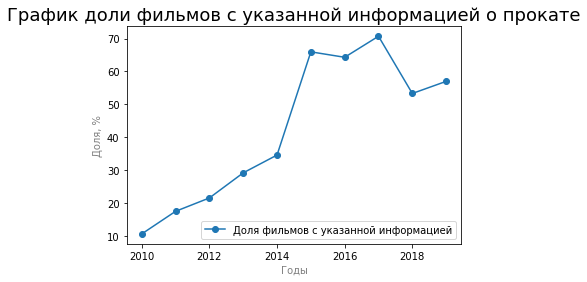

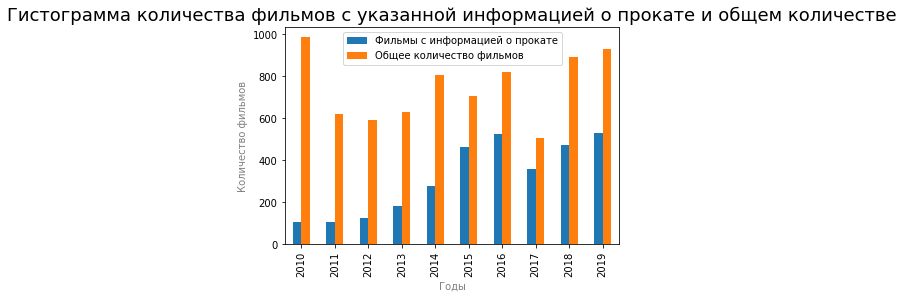

In [64]:
# создадим отдельный датасет с данными, сгруппированными по годам
df_years = df.groupby('year').agg({'box_office': ['count', 'size', 'sum']}).reset_index()
df_years['ratio'] = df_years['box_office']['count'] / df_years['box_office']['size'] * 100

# переименуем колонки для презентации
df_years.columns = ['Год проката', 'Фильмы с информацией о прокате', 'Всего фильмов', 
                    'Сумма сборов', 'Доля фильмов с указанной информацией']

# выведем датафрейм на экран
display(df_years.style.format('{:.2f}'))

# вернём колонкам короткие названия для обращения к ним
df_years.columns = ['year', 'count', 'size', 'sum', 'ratio']

# выведем на экран общую долю фильмов с указанной информацией о прокате
print('Средняя доля фильмов с указанной информацией о прокате составляет: {:.2%}'
      .format(df['box_office'].notna().mean()))

# построим график
df_years.plot(x='year', y='ratio', style='-o', label='Доля фильмов с указанной информацией')
plt.title('График доли фильмов с указанной информацией о прокате', fontsize=18)
plt.xlabel('Годы', color='grey')
plt.ylabel('Доля, %', color='grey')

# построим гистограмму
df_years.plot.bar(x='year', y=['count', 'size'],  
                  label=['Фильмы с информацией о прокате', 'Общее количество фильмов'])
plt.title('Гистограмма количества фильмов с указанной информацией о прокате и общем количестве', fontsize=18)
plt.xlabel('Годы', color='grey')
plt.ylabel('Количество фильмов', color='grey')
plt.show()

- Изучите, как менялась динамика проката по годам. В каком году сумма сборов была минимальной? А максимальной?

In [65]:
#Вычислим в какой год сумма сборов была максимальной
box_office_max=df.groupby('year')['box_office'].sum().idxmax()
print('Максимальная сумма кассовых сборов была в ', box_office_max, 'году')

Максимальная сумма кассовых сборов была в  2018 году


In [66]:
#Вычислим в какой год сумма сборов была минимальной
box_office_min=df.groupby('year')['box_office'].sum().idxmin()
print('Минимальная сумма кассовых сборов была в ', box_office_min, 'году')

Минимальная сумма кассовых сборов была в  2010 году


**В 2010 году сумма кассовых сборов минимальная, в 2018 году сумма кассовых сборов максимальная**

- С помощью сводной таблицы посчитайте среднюю и медианную сумму сборов для каждого года.

,mean,median
,box_office,box_office
year,,
2010,2.313004e+04,1700.000
2011,1.293832e+05,3000.000
2012,5.433924e+04,5660.000
2013,1.619549e+05,3522.500
2014,2.668442e+07,18160.000
2015,8.494057e+07,4920933.000
2016,9.100057e+07,3846679.410
2017,1.360328e+08,9968340.000


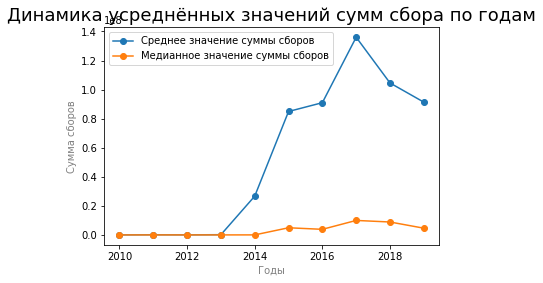

In [67]:
# выведем на экран сводную таблицу со средними и медианными значениями сумм сбора по годам
display(df.pivot_table(index='year', values='box_office', 
                       aggfunc=['mean', 'median']).sort_values(by='year'))

# построим графики по этой таблице
(
    df.pivot_table(index='year', values='box_office', aggfunc=['mean', 'median'])
    .sort_values(by='year')
    .plot(style='-o')
)
plt.title('Динамика усреднённых значений сумм сбора по годам', fontsize=18)
plt.xlabel('Годы', color='grey')
plt.ylabel('Сумма сборов', color='grey')
plt.legend(['Среднее значение суммы сборов', 'Медианное значение суммы сборов'])
plt.show()

**Видно, что благодаря отдельным фильмам состоялся бурный рост кассовых сборов, судя по медианному значению никаких выбросов не видно. Интересные и приносящие большие прибыли фильмы стали появляться в прокате с 2014 года.**

- Определите, влияет ли возрастное ограничение аудитории («6+», «12+», «16+», «18+» и т. д.) на сборы фильма в прокате в период с 2015 по 2019 год? Фильмы с каким возрастным ограничением собрали больше всего денег в прокате? Меняется ли картина в зависимости от года? Если да, предположите, с чем это может быть связано.

**Определим влияет ли возрастное ограничение на сборы фильма в прокате в период 2015 - 2019 годы.**

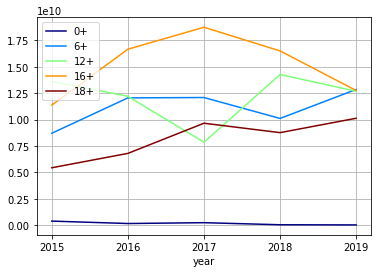

In [68]:
from_age_to_income = (
    df.loc[(df['box_office'] != 0) & (df['year'] >= 2015)]
    .pivot_table(
        index='year',
        columns='age_restriction',
        values='box_office',
        aggfunc='sum',
    )
    .rename(
        columns={
            '«0+» - для любой зрительской аудитории': '0+',
            '«12+» - для детей старше 12 лет': '12+',
            '«16+» - для детей старше 16 лет': '16+',
            '«18+» - запрещено для детей': '18+',
            '«6+» - для детей старше 6 лет': '6+',
        }
    )
    .reindex(columns=['0+', '6+', '12+', '16+', '18+'])
)

from_age_to_income.plot(
    grid=True, colormap='jet', xticks=([2015, 2016, 2017, 2018, 2019])
)
plt.legend(loc='upper left');

**В 2015 году наибольшие сборы были у фильмов с рейтингом «12+», а наименьшее «0+» , в 2019 году эта картина изменилась, почти у всех рейтингов одинаковые кассовые сборы, кроме так же минимальных «0+»**

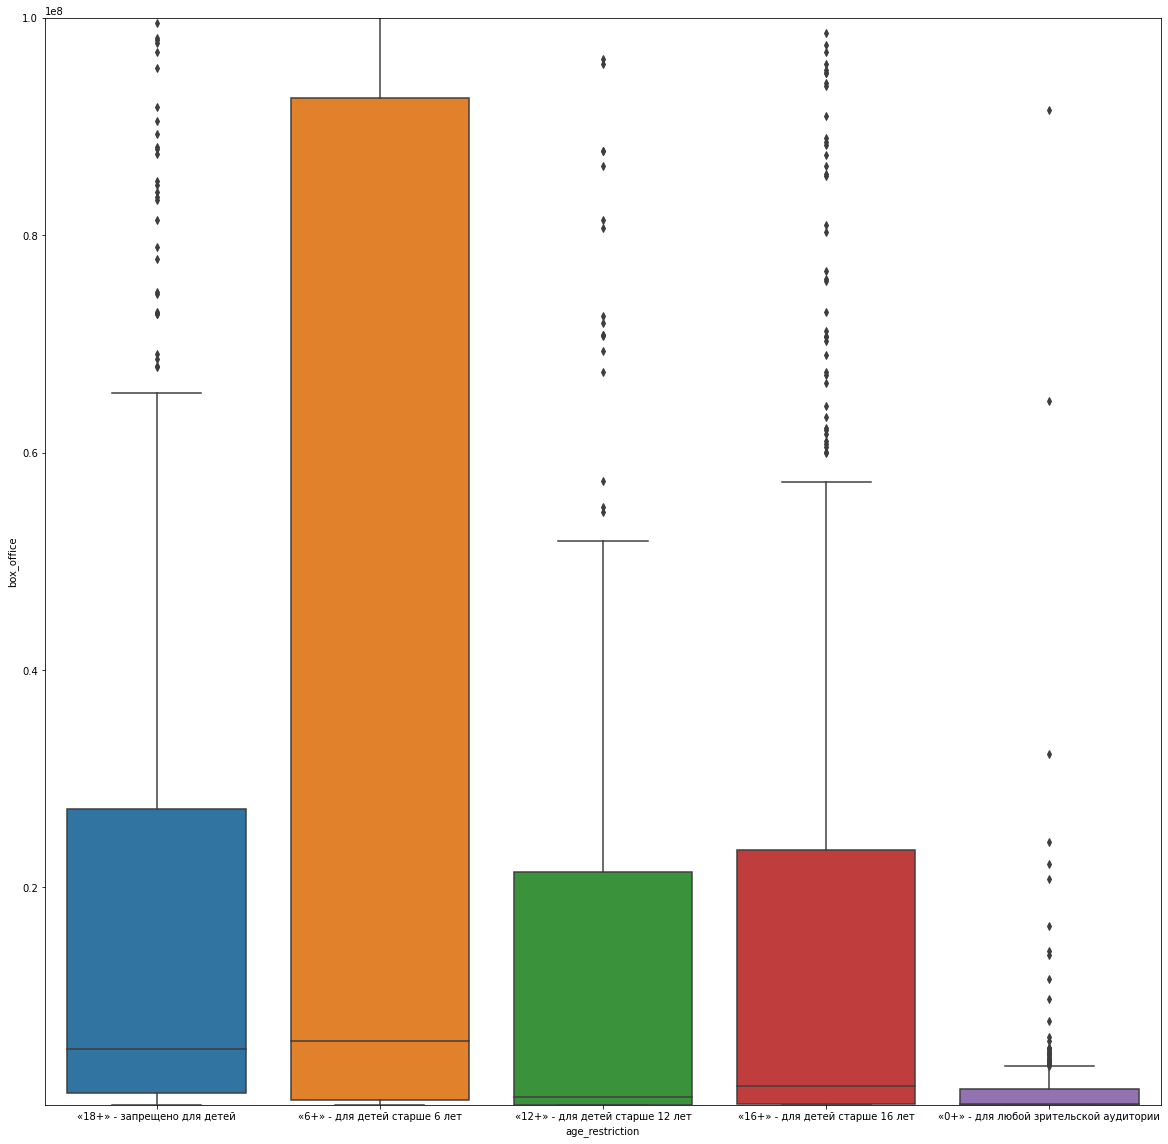

In [84]:
df.groupby('age_restriction')[['box_office']].median()
plt.figure(figsize=(20,20))
sns.boxplot(x='age_restriction', y='box_office', data=df)
plt.ylim(0.4,100000000)
plt.show()


In [70]:
#Определим фильмы с каким возрастным ограничением собрали больше всего денег в прокате.
age_restriction_max=df.groupby('age_restriction')['box_office'].sum().idxmax()
age_restriction_max

'«16+» - для детей старше 16 лет'

In [71]:
#Определим влияет ли возрастное ограничение на сборы в разные годы.
age_restriction_max_on_year=df.groupby('age_restriction').agg({'box_office': 'sum', 'year': 'count'}).idxmax()
age_restriction_max_on_year

box_office    «16+» - для детей старше 16 лет
year          «16+» - для детей старше 16 лет
dtype: object

**Категория фильмов «16+» самая прибыльная не зависимо от года, кроме 2015**

### Шаг 4. Исследуйте фильмы, которые получили государственную поддержку

На этом этапе нет конкретных инструкций и заданий — поищите интересные закономерности в данных. Посмотрите, сколько выделяют средств на поддержку кино. Проверьте, хорошо ли окупаются такие фильмы, какой у них рейтинг.

**Определем текущие тренды в прокате, какие фильмы наиболее популярны.**

,box_office
main_genres,
фантастика,5.098643e+10
мультфильм,4.069103e+10
боевик,2.759867e+10
фэнтези,2.650874e+10
комедия,2.447644e+10


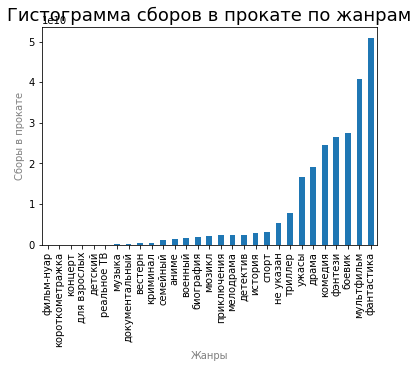

In [72]:
display(pd.DataFrame(df.groupby('main_genres')['box_office']
                     .agg('sum').sort_values(ascending=False)).head())

# гистограмма сборов в прокате по жанрам
df.groupby('main_genres')['box_office'].agg('sum').sort_values().plot.bar()
plt.title('Гистограмма сборов в прокате по жанрам', fontsize=18)
plt.xlabel('Жанры', color='grey')
plt.ylabel('Сборы в прокате', color='grey')
plt.show()

**Видно что фантастика в тренде. Посмотрим как влияет финансирование на прокаты.**

In [73]:
df.loc[df['financing_source'] != 'unknown'].pivot_table(
    index='financing_source', values='title', aggfunc='count'
).sort_values(by='title', ascending=False)

,title
financing_source,
Министерство культуры,164
Фонд кино,146
"Министерство культуры, Фонд кино",22


In [74]:
mask_len = df.loc[df['financing_source'] != 'unknown']
print(f'Количество фильмов, получивших государственную поддержку: {len(mask_len)} фильма')
print(f'Общая сумма государственного финансирования: '\
      f'{mask_len.refundable_sum .sum():,} ₽ за '\
      f'{len(mask_len.year.unique())} лет')

Количество фильмов, получивших государственную поддержку: 332 фильма
Общая сумма государственного финансирования: 20,200,688,312.0 ₽ за 7 лет


In [75]:
df.groupby('main_genres').agg({'financing_source' : lambda x : (x != 'unknown').mean(),
                                'title' : 'count'})[lambda x : x['title'] > 10] \
    .style.background_gradient().format('{:.2f}')

,financing_source,title
main_genres,,
аниме,0.00,74.00
биография,0.09,33.00
боевик,0.01,617.00
военный,0.20,46.00
детектив,0.09,56.00
детский,0.14,28.00
документальный,0.00,363.00
драма,0.06,1688.00
история,0.15,26.00


**За 7 лет на государственное финансирование потрачено более 20 миллиардов рублей на 332 картины. Похоже на то, что чаще поддерживают семейные и военные фильмы, чуть меньше исторические и детские. Аниме и боевики не поддерживают**

In [76]:
# добавим столбец с коэффициентом рентабельности
df['profit_ratio'] = df['box_office'] / df['refundable_sum']

**Посмотрим на зависимости показателей**

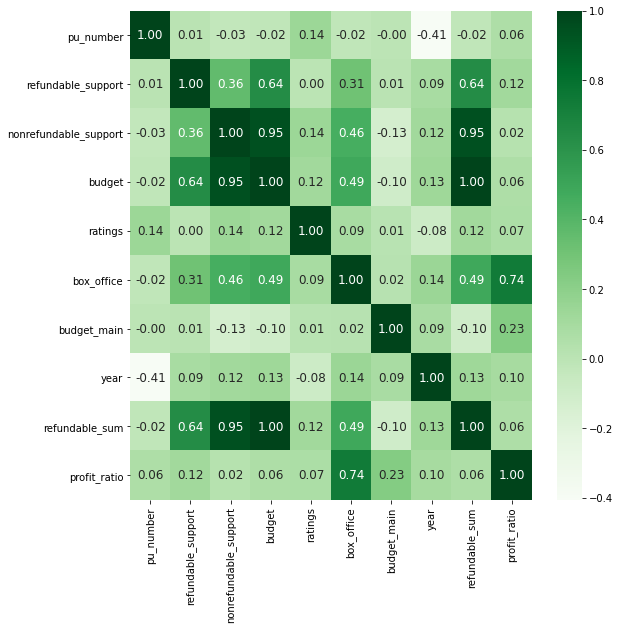

In [77]:
plt.figure(figsize=(9,9))
sns.heatmap(df.corr(), annot=True, cmap='Greens', fmt='.2f', annot_kws={'size':12})
plt.show()

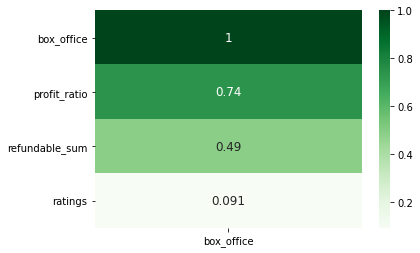

In [78]:
df_filtered = df[['refundable_sum' ,'ratings', 'box_office', 'profit_ratio']]
sns.heatmap(df_filtered.corr()[['box_office']].sort_values(by='box_office', ascending=False), cmap='Greens', 
            annot=True, annot_kws={'size':12})
plt.show()

**Видно что рейтинги не влияют на кассовые сборы. Посмотрим, что с окупаемостью фильмов с государственной поддержкой**

Картин, которые окупились: 118 
Картин, которые не окупились: 200


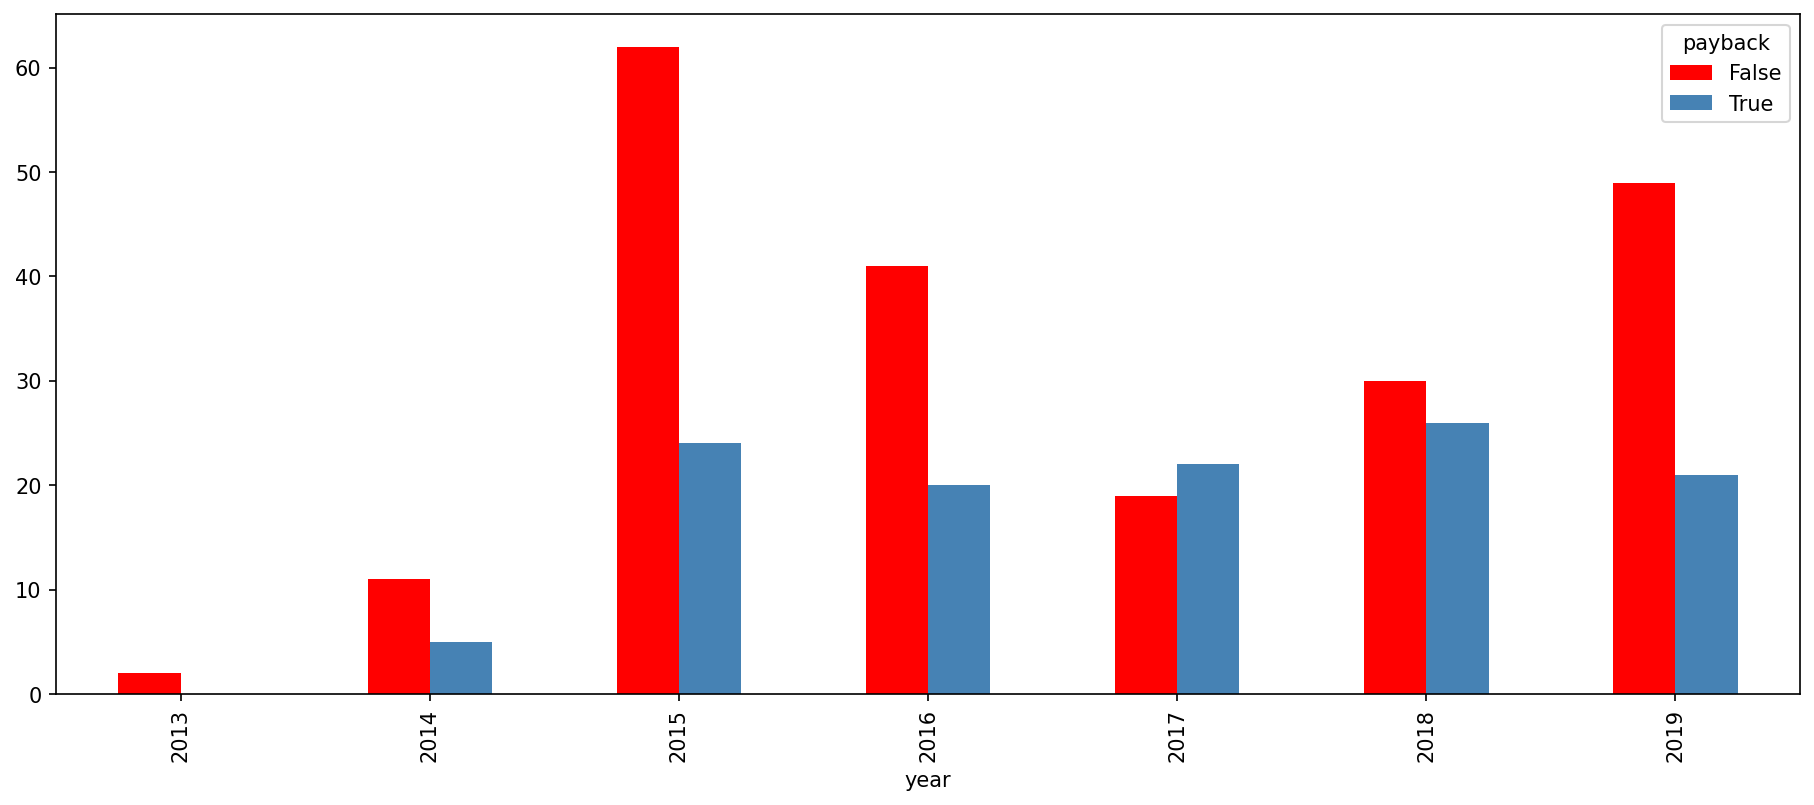

In [79]:
payback = df.loc[
    df['financing_source'] != 'unknown',
    ['title', 'year', 'ratings', 'refundable_support', 'nonrefundable_support', 'box_office'],
]

payback['payback'] = payback['box_office'] / df['refundable_sum']
payback.sort_values(by='payback', ascending=False)
print(
    'Картин, которые окупились:',
    payback.loc[payback['payback'] > 1, 'title'].count(),
    '\nКартин, которые не окупились:',
    payback.loc[payback['payback'] < 1, 'title'].count(),
)

fig, ax = plt.subplots(figsize=(15,6), dpi=150)
payback.pivot_table(index='year', columns=payback['payback'] > 1, values='title', aggfunc='count') \
    .plot(kind='bar', ax=ax, color=sns.color_palette(palette=['red','steelblue'], as_cmap=True))
plt.show()

**Окупаемых картин почти в два раза меньше общего количества финансирования. По годам соотношение окупаемости фильмов почти одинаково кроме 2017 года, окупаемых картин больше, но и общего количества финансируем не так много. 2015 год самый провальный по финансируемы картинам, 2019 не далеко ушел.**

<a id = 'g2'></a> 
<div class="alert alert-success">

    
**Факультатив**
    

    
Так же можешь посмотреть на библиотеку seaborn, в ней очень просто строятся графики, они очень хорошо оформлены и их более чем достаточно для задач анализа данных.:
    
    https://seaborn.pydata.org/index.html


Вот еще одна библиотека, позволяющая делать красивые графики
    
    https://plotly.com/python/
    
Она гораздно обширнее и в ней больше возможностей настройки а так же много дополнительных библиотек строится повер  plotly, например dash - https://dash.plotly.com/ - позволит делать интерактивные графики (ползунки, кнопки прямо в графике) и выводить их на отдельный адрес(там с сервером придется повозится), адрес которого можно скидывать кому угодно. Сейчас это врядли тебе понадобится, но на будущее, если изучишь - то большой плюс на работе будет.

Вот также статья хорошая на русском:
    
    https://habr.com/ru/company/skillfactory/blog/506974/
    
PS если хочешь быстро строить графики как в seaborn, то есть библиотека cufflinks, в статье о ней написано тоже.
    
В ней очень просто строятся графики, они очень хорошо оформлены и их более чем достаточно для задач анализа данных.
    
Ознакомится со всей палитрой графиков и категорий 'когда и что применить' можно тут:
    
    https://www.python-graph-gallery.com/
    
</div>

### Шаг 5. Напишите общий вывод

**Общий вывод:**

- Получены данные из двух таблиц и объединены в один датафрейм для удобства работы с ними.

- **Выполнена предобработка данных:**

1. Преобразованы типы данных;
2. Найдены и убраны, либо заменены корректными значениями пропуски;
3. Найдены и обрабтаны дубликаты;
4. Произведена проверка корректности данных в столбцах с категориальными и количественными значениями на наличие 5. Выбросов и нестандартных значений;
6. Добавлены необходимые для дальнейшего анализа столбцы.

- **Проведен исследовательский анализ:**
1. Огромное количество отсутствующих данных по суммам государтвенного финансирования и бюджетам, поскольку данные находятся в общем массиве с фильмами произведёнными в других странах.
2. Средняя доля фильмов с информацией о прокате составляет: 42.19%.
3. В среднем общий бюджет картины превышает сумму государственной поддержки в 2,4 раза.
4. В среднем государственная поддержка составляет 42% от общего бюджета фильма.
5. В 2010 году сумма кассовых сборов минимальная, в 2018 году сумма кассовых сборов максимальная.
6. Благодаря отдельным фильмам состоялся бурный рост кассовых сборов, судя по медианному значению никаких выбросов не видно. Интересные и приносящие большие прибыли фильмы стали появляться в прокате с 2014 года.
7. В 2015 году наибольшие сборы были у фильмов с рейтингом «12+», а наименьшее «0+» , в 2019 году эта картина изменилась, почти у всех рейтингов одинаковые кассовые сборы, кроме так же минимальных «0+».
8. Категория фильмов «16+» самая прибыльная не зависимо от года, кроме 2015 года в котором чуть выше стали сборы фильмов с возрастным рейтингом «12+».
9. Категория фильмов с рейтингом «16+» - для детей старше 16 лет, самая прибыльная во все изучаемые периоды.
10. Фильмы жанра фантастика самые популярные, чуть менее популярны мультфильмы и в среднем популярны боевики, фэнтези и комедии.

- **Исследование фильмов с государственной поддержкой:**
1. За 7 лет на государственное финансирование потрачено более 20 миллиардов рублей на 332 картины. 
2. Чаще поддерживают семейные и военные фильмы, чуть меньше исторические и детские. Аниме и боевики не поддерживают.
3. Рейтинговые оценки не влияют на кассовые сборы.
4. Окупаемых финансируемых государством картин почти в два раза меньше общего количества финансирования. По годам соотношение окупаемости фильмов почти одинаково кроме 2017 года, окупаемых картин больше, но и общего количества финансируем не так много. 2015 год самый провальный по финансируемы картинам.

<div style="border:solid Chocolate 2px; padding: 40px">

<h2>Общий вывод по проекту <a class="tocSkip"></h2>

Cпасибо за твой проект! Было приложено много усилий, чтобы довести его до конца, проделана огромная работа, и это видно невооруженным глазом! Есть несколько важных моментов, которые я отметил и которые можно было бы улучшить, подсказки ты найдешь в моих комментариях. 

**Отмечу отдельные положительные моменты проекта🙂**:
 
* Работа отличная. Ознакомься с рекомендациями, что прокачиваться дальше)


**На что стоит обратить внимание🤓**:
    
* ~[Нужно подправить предобработку данных](#p2)~
* ~[Можно дополнить некоторые пункты в исследовательском анализе](#p3)~
* ~[Можно оформить вывод](#p5)~
* советы по работе с [графиками](#g2)


**Зачел, учитывая дедлайны) Обрати подалуйста внимание на разьяснение в шаге 3. Удачи в дальнейшей учебе)**
    
    
![gif](https://media1.giphy.com/media/111ebonMs90YLu/giphy.gif?cid=ecf05e47squ85946qbqcaht8169a29teug2h55iz61x9l1k8&rid=giphy.gif&ct=g)
    